In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

/home/peidli/miniconda3/envs/sc_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

In [3]:
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Bagel2

## Transcript (disfunct)

In [36]:
input_transcript =pd.read_table('/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel2_input_transcript.txt')
input_gene =pd.read_table('/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel2_input_gene.txt')

In [37]:
input_transcript

,sgRNA,Transcript_ID,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
0,AATBC_ENST00000400385_1005,ENST00000400385,2361,2599,3522,3348,3068,2844,3879,2833,...,1235,1494,1747,1655,1494,1545,1298,1842,1277,1391
1,AATBC_ENST00000400385_1562,ENST00000400385,3330,3607,4864,4715,4947,4049,5521,3671,...,1885,2072,2450,2161,2318,2164,1775,2276,1863,2168
2,AATBC_ENST00000400385_1938,ENST00000400385,2138,2139,3108,3102,3107,2701,3749,2196,...,1199,1299,1680,1402,1473,1463,1166,1650,1139,1391
3,AATBC_ENST00000400385_2713,ENST00000400385,1995,2038,2838,2358,2162,1771,2318,1499,...,799,1175,1268,1071,1026,1157,892,1263,835,1073
4,AATBC_ENST00000400385_28,ENST00000400385,3321,3027,4610,3655,4296,3384,4974,3267,...,1518,1898,2201,1797,1975,2039,1678,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6120,RPS16_ENST00000251453_280,ENST00000251453,2782,2747,3925,2180,457,107,47,0,...,442,337,335,275,171,1198,468,230,156,154
6121,RPS16_ENST00000251453_300,ENST00000251453,2046,2117,2834,3516,2088,1164,1157,592,...,227,187,155,153,117,901,319,106,88,93
6122,RPS5_ENST00000196551_431,ENST00000196551,2713,2873,3947,3477,2315,1481,1701,921,...,821,865,787,762,653,1532,864,669,475,478
6123,RPS5_ENST00000196551_574,ENST00000196551,1846,1912,2651,2614,1972,1575,1752,1167,...,636,750,835,677,605,989,659,869,564,601


In [40]:
input_transcript.Transcript_ID.value_counts()

Transcript_ID
ENST00000400385    10
ENST00000483525    10
ENST00000414938    10
ENST00000440444    10
ENST00000598996    10
                   ..
ENST00000495032     2
ENST00000368783     2
ENST00000318059     2
ENST00000334371     2
ENST00000512737     2
Name: count, Length: 844, dtype: int64

In [39]:
input_gene.Gene.value_counts()

Gene
NT_Control    100
HOTAIRM1       42
LINC-PINT      28
BIN1           28
RAN            21
             ... 
KRTAP5-7        3
PAM16           2
NME2            2
LCE2C           2
LCE1F           2
Name: count, Length: 734, dtype: int64

In [33]:
input_transcript.value_counts('Transcript_ID')

Transcript_ID
ENST00000520395    10
ENST00000400946    10
ENST00000502066    10
ENST00000501122    10
ENST00000499203    10
                   ..
ENST00000368783     2
ENST00000334371     2
ENST00000512737     2
ENST00000495032     2
ENST00000318059     2
Name: count, Length: 844, dtype: int64

In [21]:
# 100 transcripts are unique
(input_transcript.value_counts('Transcript_ID')==1).sum()

100

In [19]:
pr_data = pd.read_table('../results/tables/pooled_screen_1_bagel_pr_transcript.tsv', index_col=0)
pr_data.info()

FileNotFoundError: [Errno 2] No such file or directory: '../results/tables/pooled_screen_1_bagel_pr_transcript.tsv'

In [ ]:
pl.figure(figsize=(4,4))
pl.plot( pr_data.Recall, pr_data.Precision, linewidth=2)
pl.xlim(0,1.01)
pl.ylim(0,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.title('BAGEL2 Transcript-wise Precision-Recall Plot')
pl.show()

In [ ]:
# ideal distribution of Bayes Factors:
# BF>3 to 5 are minimum-confidence essentials; >10 are high-confidence.
pl.figure(figsize=(4,4))
pr_data.hist('BF', bins=100)
pl.axvline(10, color='r', linestyle='--', label='BF=10')
pl.xlabel('Bayes Factor')
pl.ylabel('Number of Transcripts')
pl.legend()
pl.show()

## Gene

In [4]:
pr_data = pd.read_table('../results/tables/pooled_screen_1_bagel_pr_gene.tsv', index_col=0)
pr_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 734 entries, RAN to NT_Control
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   BF         734 non-null    float64
 1   Recall     734 non-null    float64
 2   Precision  734 non-null    float64
 3   FDR        734 non-null    float64
dtypes: float64(4)
memory usage: 28.7+ KB


In [5]:
pr_data

,BF,Recall,Precision,FDR
Gene,,,,
RAN,11277.642,0.005,1.000,0.000
FBL,5500.239,0.005,1.000,0.000
EIF4A1,4394.436,0.005,1.000,0.000
GAS5,4068.069,0.005,1.000,0.000
PPIA,3877.043,0.005,1.000,0.000
...,...,...,...,...
PCAT1,-1114.912,1.000,0.865,0.135
PCBP4,-1179.633,1.000,0.865,0.135
BIN1,-1302.457,1.000,0.865,0.135


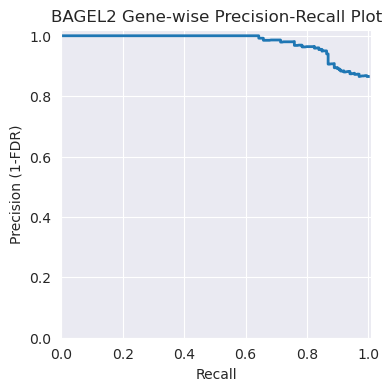

In [6]:
with sns.axes_style('darkgrid'):
    fig, ax = pl.subplots(figsize=(4,4))
pl.plot( pr_data.Recall, pr_data.Precision, linewidth=2)
pl.xlim(0,1.01)
pl.ylim(0,1.02)
pl.xlabel('Recall')
pl.ylabel('Precision (1-FDR)')
pl.title('BAGEL2 Gene-wise Precision-Recall Plot')
pl.show()

<Figure size 400x400 with 0 Axes>

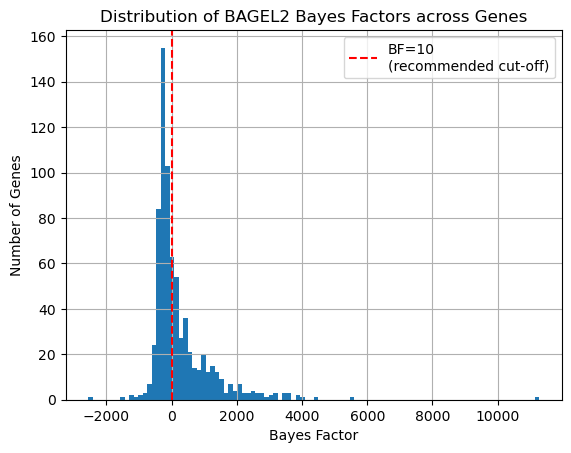

In [7]:
# ideal distribution of Bayes Factors:
# BF>3 to 5 are minimum-confidence essentials; >10 are high-confidence.
pl.figure(figsize=(4,4))
pr_data.hist('BF', bins=100)
pl.axvline(10, color='r', linestyle='--', label='BF=10\n(recommended cut-off)')
pl.xlabel('Bayes Factor')
pl.ylabel('Number of Genes')
pl.title('Distribution of BAGEL2 Bayes Factors across Genes')
pl.legend()
pl.show()

<Axes: xlabel='Median_FC', ylabel='BF'>

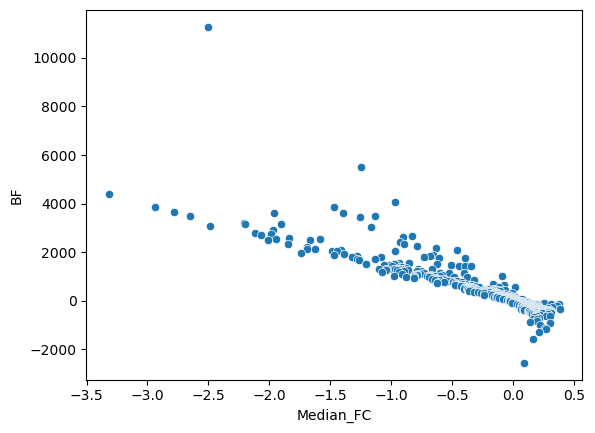

In [8]:
fc = pd.read_csv("/scratch/peidli/SYMPHONY/pooled_screen_1/bagel2/pooled_screen_1_bagel_gene.foldchange", sep='\t', index_col=0)
median_fc = fc[fc.columns[1:]].median(axis=1)
median_fc_genes = fc.groupby('GENE').mean().median(axis=1)
pr_data['Median_FC'] = median_fc_genes.loc[pr_data.index]
sns.scatterplot(y='BF', x='Median_FC', data=pr_data)

In [10]:
pr_data.to_csv('../results/tables/pooled_screen_1_bagel_pr_fc_gene.tsv', sep='\t')

# MAGeCK

In [36]:
# The sgRNA ranking results.
guide_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.sgrna_summary.txt', sep='\t', index_col=0)

In [38]:
guide_ranking.head()

,Gene,control_count,treatment_count,control_mean,treat_mean,LFC,control_var,adj_var,score,p.low,p.high,p.twosided,FDR,high_in_treatment
sgrna,,,,,,,,,,,,,,
HNRNPA1_ENST00000330752_1264,HNRNPA1,100.67/117.18/55.989/67.096/79.897/45.205/742....,1920.8,100.67,1920.8,4.2404,172250.0,62197.0,7.2982,1.0,2.220400e-13,4.440800e-13,2.764400e-09,True
EEF1A1_ENST00000316292_2562,EEF1A1,204.16/63.238/112.61/117.42/59.923/87.898/682....,1545.7,117.42,1545.7,3.7072,98968.0,72542.0,5.3030,1.0,8.517900e-08,1.703600e-07,5.302400e-04,True
HIST1H2BN_ENST00000606613_239,HIST1H2BN,173.79/155/178.66/207.28/166.04/178.31/1138.7/...,1882.4,178.66,1882.4,3.3900,281540.0,110380.0,5.1281,1.0,2.076900e-07,4.153800e-07,8.619000e-04,True
RAN_ENST00000535090_322,RAN,382.45/157.48/149.72/117.42/107.36/151.94/1648...,1725.2,157.48,1725.2,3.4453,736550.0,97290.0,5.0262,1.0,3.607800e-07,7.215700e-07,9.677200e-04,True
ACTG1_ENST00000573283_1731,ACTG1,610.79/348.43/262.33/295.94/248.43/261.18/1415...,2664.0,348.43,2664.0,2.9310,422260.0,215260.0,4.9908,1.0,3.886400e-07,7.772900e-07,9.677200e-04,True


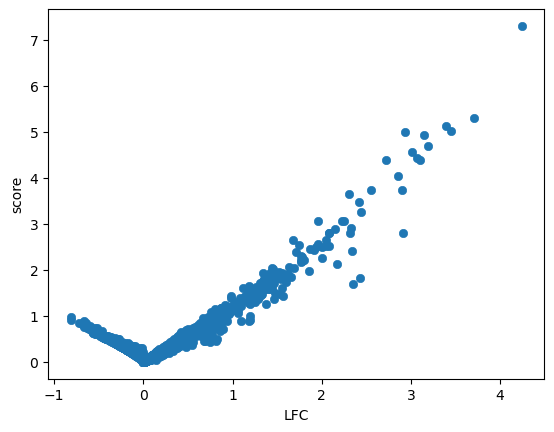

In [37]:
sns.scatterplot(data=tab, x='LFC', y='score', edgecolor=None)
pl.show()

In [40]:
# The gene ranking results.
gene_ranking = pd.read_csv('../results/mageck/pooled_screen_1_mageck.gene_summary.txt', sep='\t', index_col=0)

In [41]:
gene_ranking.head()

,num,"Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr",...,"sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|score","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|p-value","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|fdr","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|rank","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|goodsgrna","sym-03-03-TP6_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|pos|lfc"
id,,,,,,,,,,,,,,,,,,,,,
ATP5F1D,14,4.795600e-07,0.000025,0.018116,1,6,-0.214260,0.63861,0.68762,1.0,...,0.000009,228,2,-0.027214,0.86390,0.94009,1.0,591,0,-0.027214
PCBP4,21,1.205300e-05,0.000834,0.153080,2,7,-0.233070,0.99986,1.00000,1.0,...,0.579716,718,0,-0.004687,0.45906,0.72722,1.0,321,0,-0.004687
COX8A,7,2.281700e-05,0.000271,0.068841,3,2,-0.101640,0.82811,0.92557,1.0,...,0.000009,316,1,-0.109830,0.35616,0.51852,1.0,253,0,-0.109830
NAA10,14,8.351800e-05,0.002907,0.351147,4,5,-0.155820,0.68690,0.68763,1.0,...,0.000009,278,2,-0.150320,0.67994,0.83514,1.0,475,0,-0.150320
ASB17,7,8.411100e-05,0.000281,0.068841,5,2,-0.019419,0.74969,0.89024,1.0,...,0.579716,594,0,0.055685,0.13486,0.24757,1.0,91,0,0.055685


In [49]:
df = gene_ranking.reset_index().set_index(['id', 'num'])

In [73]:
df.columns = pd.MultiIndex.from_arrays([
    [x.split('_vs_')[0] for x in df.columns],
    [x.split('|')[1] for x in df.columns],
    [x.split('|')[2] for x in df.columns]
])

<Axes: ylabel='id-num'>

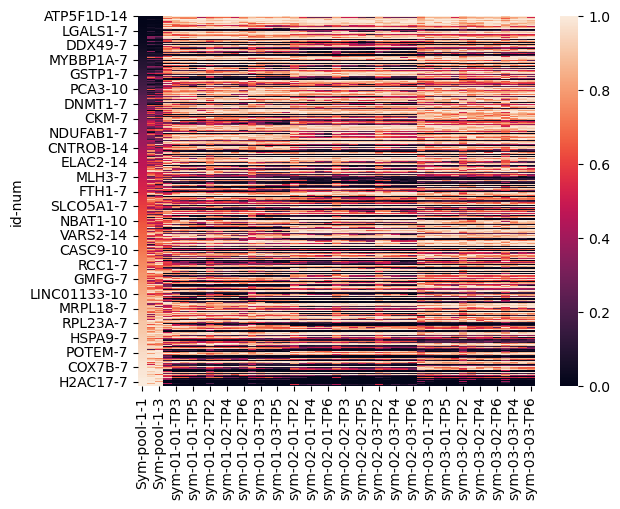

In [82]:
sns.heatmap(df.T.loc[:, 'neg', 'score'].T)

In [79]:
df.T.head(10)

id                               ATP5F1D       PCBP4       COX8A       NAA10  \
num                                   14          21          7           14   
Sym-pool-1-1 neg score      4.795600e-07    0.000012    0.000023    0.000084   
                 p-value    2.468100e-05    0.000834    0.000271    0.002907   
                 fdr        1.811600e-02    0.153080    0.068841    0.351147   
                 rank       1.000000e+00    2.000000    3.000000    4.000000   
                 goodsgrna  6.000000e+00    7.000000    2.000000    5.000000   
                 lfc       -2.142600e-01   -0.233070   -0.101640   -0.155820   
             pos score      6.386100e-01    0.999860    0.828110    0.686900   
                 p-value    6.876200e-01    1.000000    0.925570    0.687630   
                 fdr        1.000000e+00    1.000000    1.000000    1.000000   
                 rank       3.330000e+02  730.000000  500.000000  365.000000   

id                               ASB17       LSM11       PCAT1      CHCHD7  \
num                                 7           7           20          21   
Sym-pool-1-1 neg score        0.000084    0.000248    0.000759    0.000844   
                 p-value      0.000281    0.002611    0.008258    0.009522   
                 fdr          0.068841    0.351147    0.351147    0.351147   
                 rank         5.000000    6.000000    7.000000    8.000000   
                 goodsgrna    2.000000    2.000000    3.000000    4.000000   
                 lfc         -0.019419   -0.126870   -0.154400   -0.060956   
             pos score        0.749690    0.613010    0.986660    0.976530   
                 p-value      0.890240    0.790640    0.998670    0.995910   
                 fdr          1.000000    1.000000    1.000000    1.000000   
                 rank       424.000000  303.000000  692.000000  672.000000   

id                                ELOB   FOXC2-AS1  ...     HNRNPA1  \
num                                 14          10  ...          7    
Sym-pool-1-1 neg score        0.001245    0.001464  ...    0.998860   
                 p-value      0.010193    0.016670  ...    0.986820   
                 fdr          0.351147    0.351147  ...    1.000000   
                 rank         9.000000   10.000000  ...  724.000000   
                 goodsgrna    4.000000    3.000000  ...    0.000000   
                 lfc         -0.139490   -0.232310  ...    1.025500   
             pos score        0.965490    0.996340  ...    0.000006   
                 p-value      0.993310    0.999810  ...    0.000005   
                 fdr          1.000000    1.000000  ...    0.000025   
                 rank       651.000000  715.000000  ...    4.000000   

id                              NUP133      H2AC17        EIF4A1      NFE2L2  \
num                                 7           7             7           7    
Sym-pool-1-1 neg score        0.999270    0.999580  9.997000e-01    0.999720   
                 p-value      0.989870    0.995080  9.963900e-01    0.996390   
                 fdr          1.000000    1.000000  1.000000e+00    1.000000   
                 rank       725.000000  726.000000  7.270000e+02  728.000000   
                 goodsgrna    0.000000    0.000000  0.000000e+00    0.000000   
                 lfc          0.039238    0.202650  1.562600e+00    0.131890   
             pos score        0.224910    0.125880  2.194500e-07    0.280100   
                 p-value      0.000005    0.000005  4.936200e-06    0.000005   
                 fdr          0.000025    0.000025  2.500000e-05    0.000025   
                 rank       117.000000   88.000000  2.000000e+00  135.000000   

id                               RPS14        RPS5      TMSB4X        DDX5  \
num                                 14          7           7           7    
Sym-pool-1-1 neg score        0.999930    0.999940    0.999950    1.000000   
                 p-value      0.996390    0.999190    

In [53]:
df.columns

Index(['Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|score',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|p-value',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|fdr',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|rank',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|goodsgrna',
       'Sym-pool-1-1_vs_sym-01-01-TP1,sym-01-02-TP1,sym-01-03-TP1,sym-02-01-TP1,sym-02-02-TP1,sym-02-03-TP1,sym-03-01-TP1,sym-03-02-TP1,sym-03-03-TP1|neg|lfc',
       'Sym-pool-1-1_vs_sym

# Counts

In [5]:
# df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [6]:
df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1235,1494,1747,1655,1494,1545,1298,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1885,2072,2450,2161,2318,2164,1775,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1199,1299,1680,1402,1473,1463,1166,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,799,1175,1268,1071,1026,1157,892,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1518,1898,2201,1797,1975,2039,1678,2248,1576,1842


In [7]:
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1' 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]